In [5]:
import tkinter as tk
from tkinter import filedialog
import time
import pandas as pd
import numpy as np
#!pip install matplotlib
import matplotlib.pyplot as plt
from tkinter import messagebox
import threading
import os

In [ ]:
#weitere Inputs

P_PV_mmp = 1000  #kWpeak --> wenn =1000 -> 1 MWpeak

In [ ]:
#excel datei importieren

df = pd.read_excel('EV-Analyse_WIP.xlsx', sheet_name='SimBatt-Input')

#  Auslesen relevanter Serien aus df und Konvertierung zu np array
P_PVspez = pd.Series( df.loc[0:35040, 'PV-Erzeugungsprofil in kW/kWp'])  # kW/ 1 kWp
P_PV = P_PVspez*P_PV_mmp #kW

P_PVspez =  P_PVspez.to_numpy()
P_PV = P_PV.to_numpy()

P_PV


array([-1.00342936, -1.00342936, -1.00342936, ..., -1.00342936,
       -0.75257202, -0.50171468], shape=(35040,))

In [46]:
# Lastprofil
P_Load = pd.Series( df.loc[0:35040, 'Last in kWh'])#
P_Load =  P_Load.to_numpy()

P_PV_Steps = pd.Series( df.loc[0:9,'PV: Leistungsschritte in kWp'])
P_PV_Steps =  P_PV_Steps.to_numpy()
E_Batt_Steps = pd.Series( df.loc[0:9,'Speicher: Kapazität in kWh'])
E_Batt_Steps =  E_Batt_Steps.to_numpy()
P_Batt_Steps = pd.Series( df.loc[0:9,'Speicher: Leistung in kW'])
P_Batt_Steps =  P_Batt_Steps.to_numpy()
Eta_Batt = pd.Series( df.at[0, 'Speicher: Wirkungsgrad in %'])
Eta_Batt =  Eta_Batt.to_numpy()
Eta_WRBatt = pd.Series( df.at[0, 'Speicher WR: Wirkungsgrad in %'])
Eta_WRBatt =  Eta_WRBatt.to_numpy()
SCHRITT = pd.Series( df.at[0, 'Schrittweite'])
SCHRITT =  SCHRITT.to_numpy()

P_BATTMAX = P_Batt_Steps[0] # wird immer pro Iteration neu gesetzt --> kommt von P_Batt_Steps
E_BATTMAX = E_Batt_Steps[0] # wird immer pro Iteration neu gesetzt --> kommt von E_Batt_Steps


In [42]:
# def SimPVdirekt(self):

# Initialisierung Variable
P_PVdirekt = np.zeros(len( P_Load))

#  Startzeit-Endzeit-Schrittweite
t_START = 0
T_END = len( P_Load)

# PV-Direktverbrauch berechnen
for t in range( t_START, T_END):
     if  P_PV[t] > 0:
          P_PVdirekt[t] = min( P_PV[t], P_Load[t])
     else:
          P_PVdirekt[t] = 0

P_PVdirekt


array([0., 0., 0., ..., 0., 0., 0.], shape=(35040,))

In [ ]:
#def SimBatEVO(self):

#  Differenzleistung 
P_DIFF =  P_PV -  P_Load

# #  Startzeit-Endzeit-Schrittweite
# t_START = 0
# T_END = len( P_Load)

# Vorinitialisierung benötigter Variablen
P_BATTIN = np.zeros(len( P_Load))
P_BATTOUT = np.zeros(len( P_Load)) 
P_BATT = np.zeros(len( P_Load))
P_BS = np.zeros(len( P_Load)) 
E_BATT = np.zeros(len( P_Load))
SOC = np.zeros(len( P_Load))
P_Netz = np.zeros(len( P_Load))


#  PV-Speichersimulation

for i in range(len(E_Batt_Steps)):  # Schleife für verschiedene Speichergrößen
     E_BATTMAX = E_Batt_Steps[i]
     for j in range(len(P_Batt_Steps)):  # Schleife für verschiedene Speicherleistungen
          P_BATTMAX = P_Batt_Steps[j]        

          # Block von Jonathan:
          for t in range( t_START,  T_END):     
               #  Batterieladung
               if  P_DIFF[t] > 0:
                    P_BATTIN[t] = min((min( P_BATTMAX, P_DIFF[t])* Eta_WRBatt), ( E_BATTMAX*(1- SOC[t-1])/ SCHRITT/ Eta_Batt))
               #Batterieentladung
               elif   P_DIFF[t] < 0:
                    P_BATTOUT[t] = -min((min( P_BATTMAX, - P_DIFF[t])/ Eta_WRBatt), ( E_BATTMAX* SOC[t-1]/ SCHRITT))

               # Batteriespeicherleistung
               P_BATT[t] =  P_BATTIN[t]+ P_BATTOUT[t]

               #  Batteriesystemleistung
               P_BS[t] =  P_BATTIN[t]/ Eta_WRBatt +  P_BATTOUT[t]* Eta_WRBatt

               #  Gespeicherte Energie
               E_BATT[t] =  E_BATT[t-1] + ( P_BATTIN[t]* Eta_Batt +  P_BATTOUT[t])* SCHRITT

               #  SOC bestimmen
               SOC[t] =  E_BATT[t]/ E_BATTMAX
     print('simulation fertig i=%d, j=%d' % (i, j))



C:\Users\CasparGross\AppData\Local\Temp\ipykernel_20228\2462604142.py:34: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  P_BATTOUT[t] = -min((min( P_BATTMAX, - P_DIFF[t])/ Eta_WRBatt), ( E_BATTMAX* SOC[t-1]/ SCHRITT))
C:\Users\CasparGross\AppData\Local\Temp\ipykernel_20228\2462604142.py:40: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  P_BS[t] =  P_BATTIN[t]/ Eta_WRBatt +  P_BATTOUT[t]* Eta_WRBatt
C:\Users\CasparGross\AppData\Local\Temp\ipykernel_20228\2462604142.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before per

simulation fertig i=0, j=9
simulation fertig i=1, j=9
simulation fertig i=2, j=9
simulation fertig i=3, j=9
simulation fertig i=4, j=9
simulation fertig i=5, j=9
simulation fertig i=6, j=9
simulation fertig i=7, j=9
simulation fertig i=8, j=9
simulation fertig i=9, j=9


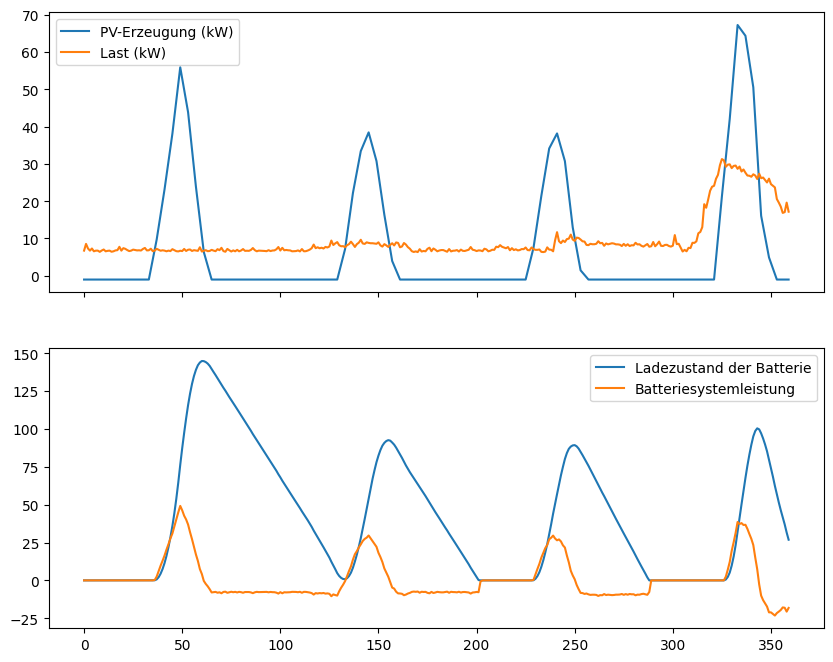

In [68]:
# kurz einmal visualisieren, um zu checken, ob Werte sinnvoll aussehen

figure, ax = plt.subplots(2,1, figsize=(10,8), sharex=True)
ax[0].plot(P_PV[0:360], label='PV-Erzeugung (kW)')
ax[0].plot(P_Load[0:360], label='Last (kW)')
ax[0].legend()

ax[1].plot(E_BATT[0:360],label ='Ladezustand der Batterie')
ax[1].plot(P_BS[0:360],label ='Batteriesystemleistung')
ax[1].legend()


In [ ]:
def SaveSimBat(self):
     P_PV_BS_Variation_trans = np.transpose( P_PV_BS_Variation)
     df2Excel = pd.DataFrame(P_PV_BS_Variation_trans)
    with pd.ExcelWriter( Path, mode='a', if_sheet_exists='replace', engine='openpyxl') as writer:
         df2Excel.to_excel(writer, sheet_name='SimBatt-Output')


In [ ]:
#Visualisierung (aus anderer Datei)
# ist aber nur Test, ob Batteriewerte sinnvoll sind oder ob sie auch negativ werden

xpoints = np.arange(35040)
ypoints = BS1.E_BATT[BS1.E_BATT<0] #
plt.plot(xpoints, ypoints)
plt.show()
#BS1,E_BATT_Out = sum(BS1,P_BATT)*BS1,SCHRITT


NameError: name 'BS1' is not defined